# Hough Lines and circles


We start by importing the necessary packages:

In [9]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.cm as cm

We'll now load in the image checkers.jpg and display it.

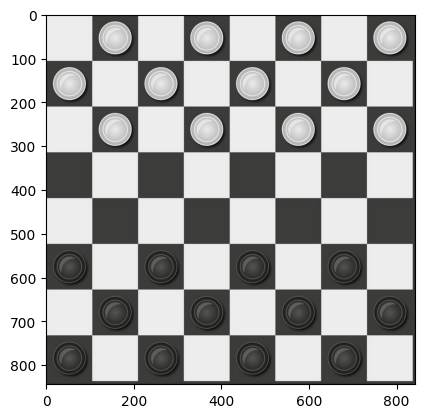

In [10]:
# Load the checkerboard image and fix its color order for display.
# cv2.imread() reads images in BGR channel order, but matplotlib expects RGB.
# Splitting into individual channels and re-merging them in reversed (R, G, B)
# order corrects this before we call plt.imshow().
img = cv2.imread('checkers.png')
# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

## Detecting lines using `cv2.HoughLines`
First we would like to detect the lines in the image using Hough Lines. OpenCV has a function to do this, called [`cv2.HoughLines`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga46b4e588934f6c8dfd509cc6e0e4545a) (Click to see the documentation). It is found that this function takes a 1-channel image as input, i.e. a grayscale image. The image is already in black and white, but it has been loaded as a rgb image, so we still need to convert it:

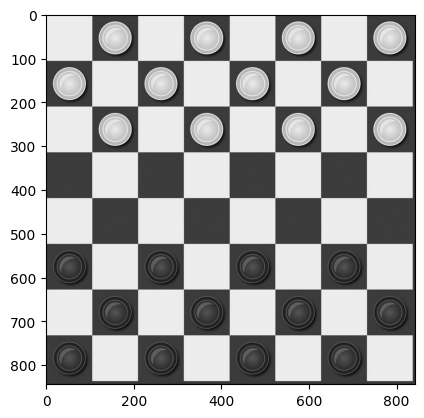

In [ ]:
# Convert the image to grayscale.
# cv2.HoughLines() requires a single-channel input. Even though this
# checkerboard image visually looks black-and-white, it was loaded as a
# 3-channel RGB image, so we still need to collapse it to one channel before
# running edge detection/Hough transform on it.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
plt.imshow(gray, cmap=cm.gray)

Next, we use the edge detection [`cv2.Canny`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) to make it easier to locate the lines. Recall the previous exercise where we used the same function and played around with the threshold.

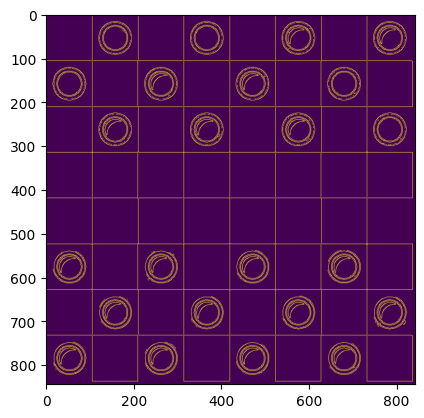

In [12]:
# Edge detection with Canny.
# The Hough transform works by looking for pixels that lie along a line
# (or circle) shape, so we first need a binary "edge map" rather than a full
# grayscale image. Canny gives us exactly that, highlighting pixels where
# intensity changes sharply (i.e. the checkerboard grid lines).
# cv2.Canny(gray, lower_threshold, upper_threshold). Here 20 and 200. Controls
# how aggressively weak edges are discarded vs. kept; These thresholds are
# tuned by trial and error for the specific image.
edges = cv2.Canny(gray, 20, 200)
plt.imshow(edges)

You might notice (but not necessarily) that many of the lines aren't found by the edge detector. In this case, it is because the picture is resized to fit the output cell. If you have the full image, the lines should show up nicely.

Now we can use the `cv2.HoughLines` function. From the documentation it is seen that it returns a vector of 
lines. As parameters, the function takes the grayscale image (`edges`), the resolution of the radius `rho` in pixels (we choose 1), the resolution of the angle `theta` in radians (we choose 1 radian) and the minimum number of intersections to detect a line (we choose 200).

In [ ]:
# Detect lines using the Hough Line Transform.
# cv2.HoughLines() looks for sets of edge pixels in 'edges' that are consistent
# with a straight line, by voting in an accumulator space parameterized by
# (rho, theta). The perpendicular distance from the origin and the angle of
# the line's normal.
#   - rho = 1: distance resolution of 1 pixel per accumulator bin.
#   - theta = np.pi/180: angle resolution of 1 degree (in radians) per bin.
#   - threshold = 200: minimum number of edge-ixel "votes" a (rho,
#     theta) combination needs to be accepted as a detected line. Higher values
#     require stronger, more clearly defined lines and reduce false positives
#     from noise.
# The result 'lines' is an array of detected lines, each given in polar form
# (rho, theta) rather than as endpoint coordinates.
lines = cv2.HoughLines(edges, 1, np.pi/180, 200)

The lines are given in polar coordinates, so we will now convert them to cartesian coordinates in order to show them in the image. Numpy has its own $\cos$ and $\sin$ functions. We make a loop that goes through every line, converts the polar coordinates to cartesian coordinates and draws the corresponding line in the original image.

In [ ]:
# Convert each detected line from polar (rho, theta) to two cartesian endpoints,
# then draw it on the image. cv2.HoughLines() returns lines in polar form, but
# cv2.line() needs two (x, y) pixel endpoints. So we have to translate between
# the two representations.
#   - (x0, y0) is the point on the line closest to the origin, computed from rho
#     and theta using basic trigonometry (x0 = r*cos(theta), y0 = r*sin(theta)).
#   - Since a "line" is infinite, we can't draw it directly. Instead we step
#     far along the line's direction in both directions (+/-1000 pixels,
#     using the direction vector (-sin(theta), cos(theta)), which is
#     perpendicular to the line's normal) to get two points (pt1, pt2) that are
#     guaranteed to lie outside the image on either side, so the drawn segment
#     fully spans across the visible image.
#   - cv2.line() then draws a straight red ((255, 0, 0) in RGB) line of thickness
#     3 between these two points directly onto the original image
for i in range(len(lines)):
    r = lines[i][0][0]
    theta = lines[i][0][1]

    x0 = r * np.cos(theta)
    y0 = r * np.sin(theta)

    pt1 = (int(x0 + 1000 * (-np.sin(theta))), int(y0 + 1000 * np.cos(theta)))
    pt2 = (int(x0 - 1000 * (-np.sin(theta))), int(y0 - 1000 * np.cos(theta)))

    cv2.line(img, pt1, pt2, (255, 0, 0), 3)

Finally, we can show the image:

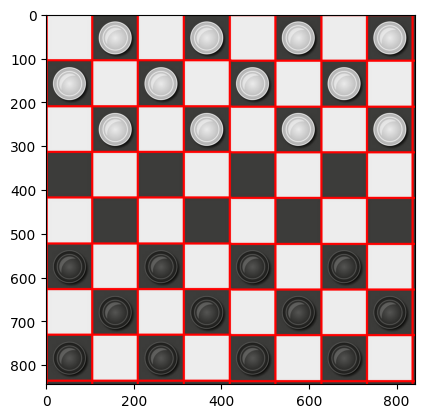

In [15]:
# Display the image with all detected lines drawn on top.
plt.imshow(img)

We can see that we have found all the lines of the checkerboard!


## Exercise 1
For the same checkerboard image, detect the checkerboard pieces using the OpenCV function [`cv2.HoughCirles`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d). Try to find all the pieces and no false circles, by tweaking the different parameters. 

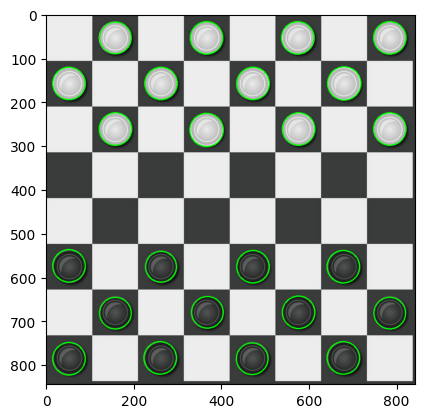

In [ ]:
#   - cv2.HOUGH_GRADIENT is the detection method (works by looking for the
#     presence of circle-shaped gradient patterns in the edges).
#   - dp=1.0: accumulator resolution equal to the image resolution.
#   - minDist=100: minimum allowed distance between detected circle centers, to
#     avoid multiple detections for the same checker piece.
#   - param1=100: the Canny upper threshold used internally for edge detection
#     as part of the circle search.
#   - param2=50: accumulator threshold for circle centers. Higher means
#     stricter, more confident detections.
#   - minRadius/maxRadius=30/50: restricts the search to circles whose radius
#     falls in this pixel range, matching the expected size of the checker
#     pieces, to avoid detecting circles that are too small/large to be real pieces.
# After detection, circle parameters (center x, center y, radius) are rounded
# to whole pixel numbers with np.around(), then each detected circle is drawn
# in green ((0, 255, 0) in RGB) with thickness 2 directly on the image.
img = cv2.imread('checkers.png')
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1.0, minDist=100, param1=100, param2=50, minRadius=30, maxRadius=50)
circles = np.uint16(np.around(circles))

for i in range(circles.shape[1]):
    cv2.circle(img, (circles[0, i, 0], circles[0, i, 1]), circles[0, i, 2], (0, 255, 0), 2)

plt.imshow(img)